# Sales Pattern Analytics for a Retail Pharmacy - Reproducible Pipeline

Companion notebook to the BDM capstone (IITM Online BS). It re-implements the project's analysis pipeline end to end:

| Step | Technique |
|---|---|
| 1 | Data checks and descriptive statistics |
| 2 | Customer segmentation - RFM (quartile scoring) |
| 3 | Product associations - market basket analysis (Apriori: support, confidence, lift) |
| 4 | Inventory priority - ABC revenue classes x XYZ demand-variability classes |
| 5 | Forecasting - linear trend validated on a held-out month (MAE, MAPE) |
| 6 | Safety stock and reorder points for high-revenue, unstable-demand products |

> **Important - read before using the results.** The business's real transaction data was shared under an academic-use-only authorisation and is **not** published. This notebook therefore runs on a **synthetic dataset** with the same structure (invoices, customers, products, categories, six months of dates). It is an illustrative re-implementation of the method, **not the original analysis code**, and its numbers will **not** match the capstone report. Segment cut-offs for the RFM score are illustrative choices. To run it on your own data, replace the generation cell with a dataframe containing the same columns.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

SEED = 42
rng = np.random.default_rng(SEED)

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Synthetic data

Structure mirrors a pharmacy billing export: one row per invoice line.
Built-in patterns so every technique has something to find: some customers follow chronic-therapy regimens and refill them together (so certain products are bought together), some products have steadier demand than others, and Respiratory / Skin Care are seasonal.

In [2]:
N_CUSTOMERS, N_INVOICES = 820, 13_000
START, END = pd.Timestamp("2024-01-01"), pd.Timestamp("2024-06-30")
days = pd.date_range(START, END)

# --- products -----------------------------------------------------------------
categories = {"Diabetes": 5, "Cardiac": 5, "Vitamins": 4, "Respiratory": 4, "OTC": 4, "Skin Care": 3,
              "Antacids": 3, "Antibiotics": 3, "Neuro/Sleep": 3, "Thyroid": 2, "Pediatric": 2, "Eye/Ear": 2}
rows = [(f"{cat} Item {k}", cat) for cat, n in categories.items() for k in range(1, n + 1)]
products = pd.DataFrame(rows, columns=["Product_Name", "Category"])
products["Product_ID"] = [f"P{i:03d}" for i in range(1, len(products) + 1)]
products["Unit_Price"] = np.round(rng.lognormal(mean=4.6, sigma=0.7, size=len(products)), 2)
products.loc[0, "Unit_Price"] = 900.0            # one high-value chronic product

chronic = {"Diabetes", "Cardiac", "Thyroid", "Neuro/Sleep"}
base_pop = np.where(products["Category"].isin(chronic), 1.5, 1.0) * rng.gamma(4.0, 0.25, len(products))

# month-to-month demand multipliers: product-level volatility + seasonality
volatility = rng.choice([0.05, 0.12, 0.30], size=len(products), p=[0.5, 0.3, 0.2])
mult = np.clip(1 + rng.normal(0, 1, (len(products), 6)) * volatility[:, None], 0.3, None)
mult[(products["Category"] == "Respiratory").to_numpy()] *= np.array([1.4, 1.3, 0.8, 0.7, 0.9, 1.3])
mult[(products["Category"] == "Skin Care").to_numpy()] *= np.array([0.8, 0.7, 1.2, 1.3, 1.3, 1.0])
month_weights = base_pop[:, None] * mult
month_weights = month_weights / month_weights.sum(axis=0)          # (products, 6) selection probabilities

# --- customers: activity level and (for some) a chronic-therapy regimen ----------
activity = rng.gamma(shape=2.0, scale=1.0, size=N_CUSTOMERS)
activity = activity / activity.sum()
chronic_idx = np.flatnonzero(products["Category"].isin(chronic))
# a dozen standard chronic regimens (2-3 products) shared by many customers
chronic_w = base_pop[chronic_idx] / base_pop[chronic_idx].sum()
templates = [rng.choice(chronic_idx, size=int(rng.integers(2, 4)), replace=False, p=chronic_w) for _ in range(12)]
regimen = [templates[int(rng.integers(len(templates)))] if rng.random() < 0.6 else np.array([], dtype=int)
           for _ in range(N_CUSTOMERS)]

# --- invoices --------------------------------------------------------------------
inv_customer = np.concatenate([np.arange(N_CUSTOMERS),                       # everyone buys at least once
                               rng.choice(N_CUSTOMERS, size=N_INVOICES - N_CUSTOMERS, p=activity)])
rng.shuffle(inv_customer)
inv_date = rng.choice(days, size=N_INVOICES)
basket_size = rng.choice([1, 2, 3, 4], size=N_INVOICES, p=[0.45, 0.35, 0.15, 0.05])

lines = []
for i in range(N_INVOICES):
    c, d = inv_customer[i], pd.Timestamp(inv_date[i])
    chosen = set()
    if len(regimen[c]) and rng.random() < 0.3:                  # chronic refill: regimen items bought together
        k = min(int(basket_size[i]), len(regimen[c]))
        chosen = {int(p) for p in rng.choice(regimen[c], size=k, replace=False)}
    while len(chosen) < basket_size[i]:                         # fill the rest of the basket by popularity
        chosen.add(int(rng.choice(len(products), p=month_weights[:, d.month - 1])))
    for p in chosen:
        lines.append((f"INV{i + 1:06d}", d, f"C{c + 1:04d}", p, int(rng.integers(1, 4))))

tx = pd.DataFrame(lines, columns=["Invoice_No", "Invoice_Date", "Customer_ID", "p_idx", "Quantity"])
tx = tx.merge(products.reset_index().rename(columns={"index": "p_idx"}), on="p_idx").drop(columns="p_idx")
tx["Total_Amount"] = (tx["Quantity"] * tx["Unit_Price"]).round(2)
tx = tx.sort_values(["Invoice_Date", "Invoice_No"]).reset_index(drop=True)
tx.head()

,Invoice_No,Invoice_Date,Customer_ID,Quantity,Product_Name,Category,Product_ID,Unit_Price,Total_Amount
0,INV000040,2024-01-01,C0646,2,OTC Item 4,OTC,P022,61.77,123.54
1,INV000145,2024-01-01,C0322,2,Neuro/Sleep Item 2,Neuro/Sleep,P033,69.51,139.02
2,INV000322,2024-01-01,C0284,3,Diabetes Item 1,Diabetes,P001,900.00,"2,700.00"
3,INV000337,2024-01-01,C0117,1,Cardiac Item 5,Cardiac,P010,54.76,54.76
4,INV000441,2024-01-01,C0100,1,OTC Item 4,OTC,P022,61.77,61.77


## 2. Data checks and descriptive statistics

In [3]:
print(f"rows: {len(tx):,} | invoices: {tx.Invoice_No.nunique():,} | customers: {tx.Customer_ID.nunique():,} | "
      f"products: {tx.Product_ID.nunique()} | categories: {tx.Category.nunique()}")
print(f"missing values: {int(tx.isna().sum().sum())} | duplicate rows: {int(tx.duplicated().sum())}")
print(f"period: {tx.Invoice_Date.min().date()} to {tx.Invoice_Date.max().date()} | total revenue: {tx.Total_Amount.sum():,.2f}")

inv = tx.groupby("Invoice_No").agg(value=("Total_Amount", "sum"), items=("Product_ID", "nunique"))
stats = inv["value"].describe()[["count", "mean", "50%", "std", "min", "25%", "75%", "max"]]
stats.loc["CV %"] = inv["value"].std() / inv["value"].mean() * 100
print("\nInvoice value statistics")
print(stats.to_string())
print(f"\navg items per invoice: {inv['items'].mean():.2f} | invoices with 2+ items: {(inv['items'] >= 2).mean():.1%}")

rows: 23,466 | invoices: 13,000 | customers: 820 | products: 40 | categories: 12
missing values: 0 | duplicate rows: 0
period: 2024-01-01 to 2024-06-30 | total revenue: 7,780,171.33

Invoice value statistics
count   13,000.00
mean       598.47
50%        380.06
std        661.91
min         25.39
25%        184.00
75%        720.60
max      4,883.40
CV %       110.60

avg items per invoice: 1.81 | invoices with 2+ items: 55.4%


## 3. Customer segmentation (RFM)

Recency = days from a customer's last invoice to the day after the data ends; Frequency = distinct invoices; Monetary = total spend.
Each measure is scored 1-4 by quartile (4 = best), scores are summed (3-12) and mapped to four segments.

In [4]:
snapshot = tx["Invoice_Date"].max() + pd.Timedelta(days=1)
rfm = tx.groupby("Customer_ID").agg(
    Recency=("Invoice_Date", lambda s: (snapshot - s.max()).days),
    Frequency=("Invoice_No", "nunique"),
    Monetary=("Total_Amount", "sum"),
)
# rank(method="first") breaks ties so qcut always yields four equal-sized bins
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)   # recent = high score
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["Score"] = rfm[["R", "F", "M"]].sum(axis=1)
# illustrative cut-offs: 3-5, 6-7, 8-9, 10-12
rfm["Segment"] = pd.cut(rfm["Score"], bins=[2, 5, 7, 9, 12],
                        labels=["At-Risk/Infrequent", "Occasional", "Steady/Regular", "High-Value Loyal"])

order = ["High-Value Loyal", "Steady/Regular", "Occasional", "At-Risk/Infrequent"]
seg = (rfm.groupby("Segment", observed=True)
          .agg(Customers=("Recency", "size"), Avg_Recency=("Recency", "mean"),
               Avg_Frequency=("Frequency", "mean"), Avg_Monetary=("Monetary", "mean"), Revenue=("Monetary", "sum"))
          .loc[order])
seg["Pct_Customers"] = seg["Customers"] / seg["Customers"].sum() * 100
seg["Revenue_Share"] = seg["Revenue"] / seg["Revenue"].sum() * 100
seg.drop(columns="Revenue")

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Pct_Customers,Revenue_Share
Segment,,,,,,
High-Value Loyal,243,4.86,28.96,"18,231.13",29.63,56.94
Steady/Regular,171,9.25,15.84,"9,214.86",20.85,20.25
Occasional,183,15.95,11.11,"6,296.19",22.32,14.81
At-Risk/Infrequent,223,42.14,5.48,"2,789.53",27.20,8.00


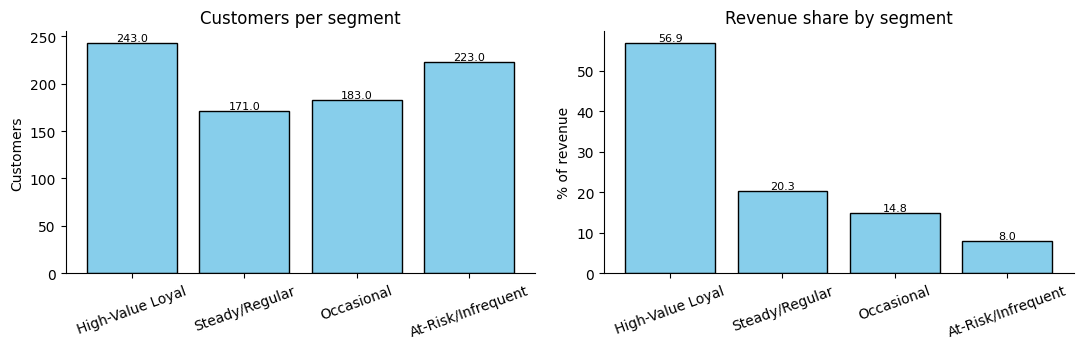

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(seg.index, seg["Customers"], color="#87CEEB", edgecolor="black")
ax[0].set_title("Customers per segment"); ax[0].set_ylabel("Customers")
ax[1].bar(seg.index, seg["Revenue_Share"], color="#87CEEB", edgecolor="black")
ax[1].set_title("Revenue share by segment"); ax[1].set_ylabel("% of revenue")
for a in ax:
    a.tick_params(axis="x", rotation=20)
    for p in a.patches:
        a.annotate(f"{p.get_height():,.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Market basket analysis

Only invoices with two or more distinct products are used. Apriori finds product sets present in at least 1% of those invoices;
rules are ranked by **lift** (how much more often two products are bought together than if they were independent; 1.0 = no association).

In [6]:
multi_ids = inv.index[inv["items"] >= 2]
sub = tx[tx["Invoice_No"].isin(multi_ids)]
basket = pd.crosstab(sub["Invoice_No"], sub["Product_Name"]) > 0
print(f"multi-item invoices: {len(basket):,} of {len(inv):,} ({len(basket) / len(inv):.1%})")

freq = apriori(basket, min_support=0.01, use_colnames=True, max_len=2)
try:
    rules = association_rules(freq, metric="lift", min_threshold=1.0)
except TypeError:                                   # newer mlxtend versions want the transaction count
    rules = association_rules(freq, num_itemsets=len(basket), metric="lift", min_threshold=1.0)

if rules.empty:
    raise ValueError("No association rules found - lower min_support or check the basket construction.")
rules["pair"] = rules.apply(lambda r: " + ".join(sorted(list(r["antecedents"]) + list(r["consequents"]))), axis=1)
top = (rules.sort_values("lift", ascending=False).drop_duplicates("pair").head(8)
            [["pair", "support", "confidence", "lift"]].reset_index(drop=True))
print(f"frequent itemsets: {len(freq)} | rules (lift > 1): {len(rules)}")
top

multi-item invoices: 7,203 of 13,000 (55.4%)
frequent itemsets: 54 | rules (lift > 1): 20


,pair,support,confidence,lift
0,Cardiac Item 4 + Neuro/Sleep Item 1,0.02,0.23,3.23
1,Neuro/Sleep Item 2 + Thyroid Item 2,0.04,0.23,2.41
2,Diabetes Item 3 + Diabetes Item 4,0.01,0.23,2.34
3,Cardiac Item 2 + Diabetes Item 3,0.01,0.13,2.07
4,Diabetes Item 1 + Diabetes Item 2,0.01,0.08,1.72
5,Diabetes Item 1 + Diabetes Item 5,0.04,0.29,1.50
6,Diabetes Item 2 + Diabetes Item 5,0.01,0.28,1.48
7,Cardiac Item 2 + Diabetes Item 4,0.02,0.13,1.35


10 products appear in the top pairs and account for 59.7% of revenue


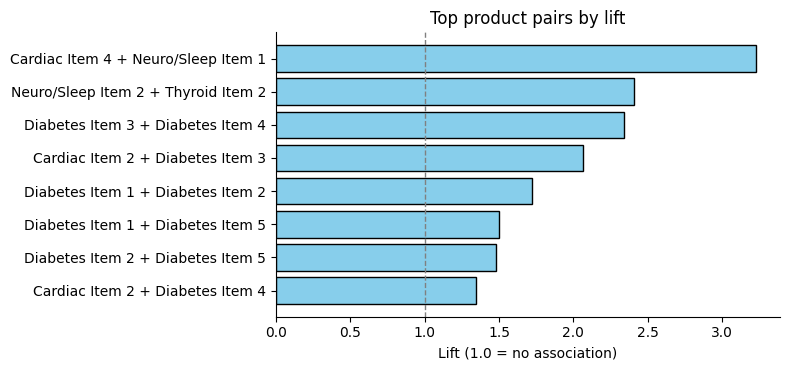

In [7]:
items = set(sum((p.split(" + ") for p in top["pair"]), []))
share = tx.loc[tx["Product_Name"].isin(items), "Total_Amount"].sum() / tx["Total_Amount"].sum()
print(f"{len(items)} products appear in the top pairs and account for {share:.1%} of revenue")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top["pair"][::-1], top["lift"][::-1], color="#87CEEB", edgecolor="black")
ax.axvline(1.0, color="grey", ls="--", lw=1)
ax.set_xlabel("Lift (1.0 = no association)"); ax.set_title("Top product pairs by lift")
plt.tight_layout(); plt.show()

## 5. ABC and ABC-XYZ inventory classification

* **ABC** - products ranked by revenue; Class A = cumulative share up to 70%, B = up to 90%, C = the rest.
* **XYZ** - coefficient of variation (CV) of monthly unit demand; X <= 20% (stable), Y <= 40% (variable), Z > 40% (highly variable).
* **AY** products (high revenue, unstable demand) carry the biggest stock-out risk.

In [8]:
prod = (tx.groupby("Product_Name").agg(Category=("Category", "first"), Revenue=("Total_Amount", "sum"))
          .sort_values("Revenue", ascending=False))
prod["Cum_Share"] = prod["Revenue"].cumsum() / prod["Revenue"].sum()
prod["ABC"] = np.where(prod["Cum_Share"] <= 0.70, "A", np.where(prod["Cum_Share"] <= 0.90, "B", "C"))

tx["Month"] = tx["Invoice_Date"].dt.to_period("M")
monthly_units = tx.pivot_table(index="Product_Name", columns="Month", values="Quantity", aggfunc="sum", fill_value=0)
prod["CV_pct"] = (monthly_units.std(axis=1, ddof=1) / monthly_units.mean(axis=1) * 100).reindex(prod.index)
prod["XYZ"] = np.where(prod["CV_pct"] <= 20, "X", np.where(prod["CV_pct"] <= 40, "Y", "Z"))
prod["ABC_XYZ"] = prod["ABC"] + prod["XYZ"]

abc = prod.groupby("ABC").agg(Products=("Revenue", "size"), Revenue=("Revenue", "sum"))
abc["Pct_Products"] = abc["Products"] / abc["Products"].sum() * 100
abc["Pct_Revenue"] = abc["Revenue"] / abc["Revenue"].sum() * 100
display(abc)

combo = prod.groupby("ABC_XYZ").agg(Products=("Revenue", "size"), Revenue=("Revenue", "sum"))
combo["Revenue_Share"] = combo["Revenue"] / combo["Revenue"].sum() * 100
combo

,Products,Revenue,Pct_Products,Pct_Revenue
ABC,,,,
A,10,"5,428,933.91",25.00,69.78
B,14,"1,507,957.03",35.00,19.38
C,16,"843,280.39",40.00,10.84


,Products,Revenue,Revenue_Share
ABC_XYZ,,,
AX,8,"4,756,673.27",61.14
AY,1,"506,510.76",6.51
AZ,1,"165,749.88",2.13
BX,11,"1,226,248.83",15.76
BY,3,"281,708.20",3.62
CX,10,"534,364.95",6.87
CY,5,"257,097.31",3.30
CZ,1,"51,818.13",0.67


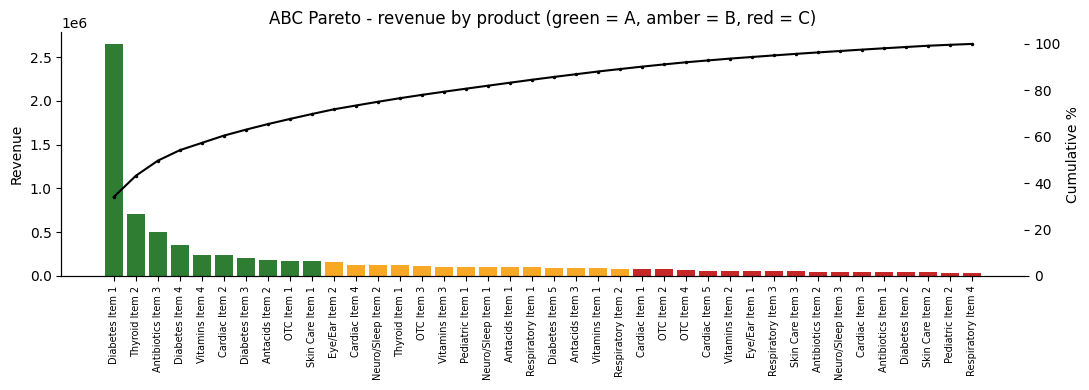

In [9]:
colors = prod["ABC"].map({"A": "#2E7D32", "B": "#F9A825", "C": "#C62828"})
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(prod)), prod["Revenue"], color=colors)
ax.set_xticks(range(len(prod))); ax.set_xticklabels(prod.index, rotation=90, fontsize=7)
ax.set_ylabel("Revenue"); ax.set_title("ABC Pareto - revenue by product (green = A, amber = B, red = C)")
ax2 = ax.twinx(); ax2.plot(range(len(prod)), prod["Cum_Share"] * 100, "k.-", ms=3)
ax2.set_ylabel("Cumulative %"); ax2.set_ylim(0, 105)
plt.tight_layout(); plt.show()

## 6. Demand forecasting with hold-out validation

A linear trend is fitted to monthly revenue. Rather than just asserting accuracy, the model is **trained on January-May and tested against the actual June value** (MAE and MAPE); the full six months are then used to project July.
With only six months of history a transparent linear trend is preferable to a seasonal model, which would overfit.

June predicted: 1,325,337.53 | actual: 1,338,372.21
MAE: 13,034.68 | MAPE: 0.97%
July forecast (full 6-month trend): 1,346,353.22


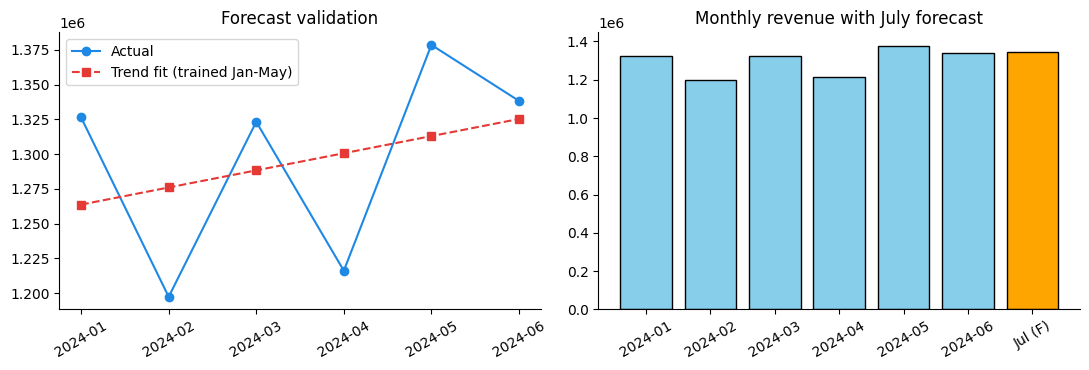

In [10]:
monthly_rev = tx.groupby("Month")["Total_Amount"].sum()
y, x = monthly_rev.to_numpy(), np.arange(1, 7)

slope, intercept = np.polyfit(x[:5], y[:5], 1)                 # train: Jan-May
pred_june, actual_june = slope * 6 + intercept, y[5]
mae = abs(actual_june - pred_june)
mape = mae / actual_june * 100

slope_f, intercept_f = np.polyfit(x, y, 1)                      # full fit: Jan-Jun
july = slope_f * 7 + intercept_f

print(f"June predicted: {pred_june:,.2f} | actual: {actual_june:,.2f}")
print(f"MAE: {mae:,.2f} | MAPE: {mape:.2f}%")
print(f"July forecast (full 6-month trend): {july:,.2f}")

labels = [str(m) for m in monthly_rev.index]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(labels, y, "o-", color="#1E88E5", label="Actual")
ax[0].plot(labels, slope * x + intercept, "s--", color="#E53935", label="Trend fit (trained Jan-May)")
ax[0].set_title("Forecast validation"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
ax[1].bar(labels + ["Jul (F)"], list(y) + [july], color=["#87CEEB"] * 6 + ["#FFA500"], edgecolor="black")
ax[1].set_title("Monthly revenue with July forecast"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 7. Safety stock and reorder points

For each high-risk (AY) product, from daily unit demand: `safety stock = Z x std(daily demand) x sqrt(lead time)` and `reorder point = mean daily demand x lead time + safety stock`,
with a 95% service level (Z = 1.65) and a 3-day replenishment lead time.

In [11]:
LEAD_TIME, Z = 3, 1.65
round_half_up = lambda v: int(np.floor(v + 0.5))

targets = prod.index[prod["ABC_XYZ"] == "AY"].tolist()
if not targets:                                                  # synthetic data may produce no AY products
    targets = prod[prod["ABC"] == "A"].sort_values("CV_pct", ascending=False).head(5).index.tolist()
    print("No AY products in this run - showing the five most variable Class-A products instead.\n")

daily = (tx.pivot_table(index="Invoice_Date", columns="Product_Name", values="Quantity", aggfunc="sum")
           .reindex(days).fillna(0))

out = []
for p in targets:
    mu, sd = daily[p].mean(), daily[p].std(ddof=1)
    ss = round_half_up(Z * sd * np.sqrt(LEAD_TIME))
    out.append({"Product": p, "Revenue": prod.loc[p, "Revenue"], "Demand_CV_pct": prod.loc[p, "CV_pct"],
                "Avg_Daily_Demand": mu, "Std_Daily_Demand": sd, "Safety_Stock": ss,
                "Reorder_Point": round_half_up(mu * LEAD_TIME + ss)})
safety = pd.DataFrame(out)
safety

,Product,Revenue,Demand_CV_pct,Avg_Daily_Demand,Std_Daily_Demand,Safety_Stock,Reorder_Point
0,Antibiotics Item 3,"506,510.76",33.58,6.25,4.05,12,31


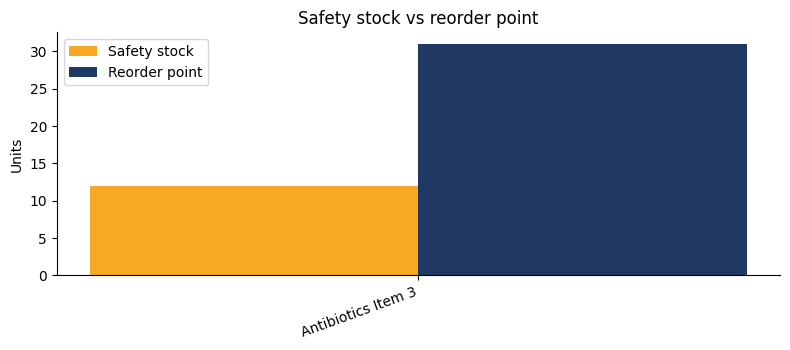

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38; idx = np.arange(len(safety))
ax.bar(idx - w / 2, safety["Safety_Stock"], w, label="Safety stock", color="#F9A825")
ax.bar(idx + w / 2, safety["Reorder_Point"], w, label="Reorder point", color="#1F3864")
ax.set_xticks(idx); ax.set_xticklabels(safety["Product"], rotation=20, ha="right")
ax.set_ylabel("Units"); ax.set_title("Safety stock vs reorder point"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Summary (this synthetic run)

In [13]:
top_seg = seg.loc[["High-Value Loyal", "Steady/Regular"]]
print(f"1. Top two RFM segments: {top_seg['Pct_Customers'].sum():.1f}% of customers -> {top_seg['Revenue_Share'].sum():.1f}% of revenue")
print(f"2. Class-A products: {int(abc.loc['A', 'Products'])} of {len(prod)} -> {abc.loc['A', 'Pct_Revenue']:.1f}% of revenue")
print(f"3. Strongest product pair by lift: {top.loc[0, 'pair']} (lift {top.loc[0, 'lift']:.2f})")
print(f"4. Hold-out forecast error (total monthly revenue): {mape:.2f}% MAPE")
print(f"5. Stock-out risk products analysed: {len(safety)}")
print("\nThese figures come from synthetic data and illustrate the method; they are not the business's results.")

1. Top two RFM segments: 50.5% of customers -> 77.2% of revenue
2. Class-A products: 10 of 40 -> 69.8% of revenue
3. Strongest product pair by lift: Cardiac Item 4 + Neuro/Sleep Item 1 (lift 3.23)
4. Hold-out forecast error (total monthly revenue): 0.97% MAPE
5. Stock-out risk products analysed: 1

These figures come from synthetic data and illustrate the method; they are not the business's results.
